# EJERCICIO

## DEFINICIÓN DEL PROBLEMA

**Vamos a trabajar con un dataframe sobre los datos de propinas que viene en la librería seaborn para intentar predecir que propina dejará una persona a partir de ciertos datos como sexo, importe...**

**Como criterio de evaluación vamos a usar RCME.**

## RECOPILACIÓN Y PREPARACIÓN DE LOS DATOS

### OBTENER LOS DATOS

In [1]:
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,  StandardScaler, FunctionTransformer
from sklearn.pipeline import make_pipeline
df_tips = sns.load_dataset('tips')

Significado de las columnas:
1. `total_bill`: Esta columna representa el monto total de la factura de una transacción en el restaurante, incluyendo la comida y las bebidas.

2. `tip`: En esta columna se registra la cantidad de propina que se dio en esa transacción.

3. `sex`: Indica el sexo del camarero o camarera que atendió la mesa (por ejemplo, "Male" para masculino y "Female" para femenino).

4. `smoker`: Esta columna indica si los comensales eran fumadores o no fumadores en la mesa (por ejemplo, "Yes" para fumadores y "No" para no fumadores).

5. `day`: Registra el día de la semana en el que se realizó la transacción (por ejemplo, "Thur" para jueves, "Fri" para viernes, "Sat" para sábado y "Sun" para domingo).

6. `time`: Indica si la transacción fue durante el almuerzo o la cena (por ejemplo, "Lunch" para almuerzo y "Dinner" para cena).

7. `size`: Representa el número de comensales en la mesa.

### EXPLORAR LOS DATOS

In [2]:
display(df_tips.shape)
display(df_tips.head(15))

display(df_tips.info())
display(df_tips.describe(include=["number", "category"]))

# Parece que la mayoría son cenas de personas no fumadoras en sábados, pero representaremos los datos en gráficas para ver la distribución real

(244, 7)

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
5,25.29,4.71,Male,No,Sun,Dinner,4
6,8.77,2.00,Male,No,Sun,Dinner,2
7,26.88,3.12,Male,No,Sun,Dinner,4
8,15.04,1.96,Male,No,Sun,Dinner,2
9,14.78,3.23,Male,No,Sun,Dinner,2


<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


None

,total_bill,tip,sex,smoker,day,time,size
count,244.000000,244.000000,244,244,244,244,244.000000
unique,NaN,NaN,2,2,4,2,NaN
top,NaN,NaN,Male,No,Sat,Dinner,NaN
freq,NaN,NaN,157,151,87,176,NaN
mean,19.785943,2.998279,NaN,NaN,NaN,NaN,2.569672
std,8.902412,1.383638,NaN,NaN,NaN,NaN,0.951100
min,3.070000,1.000000,NaN,NaN,NaN,NaN,1.000000
25%,13.347500,2.000000,NaN,NaN,NaN,NaN,2.000000
50%,17.795000,2.900000,NaN,NaN,NaN,NaN,2.000000
75%,24.127500,3.562500,NaN,NaN,NaN,NaN,3.000000


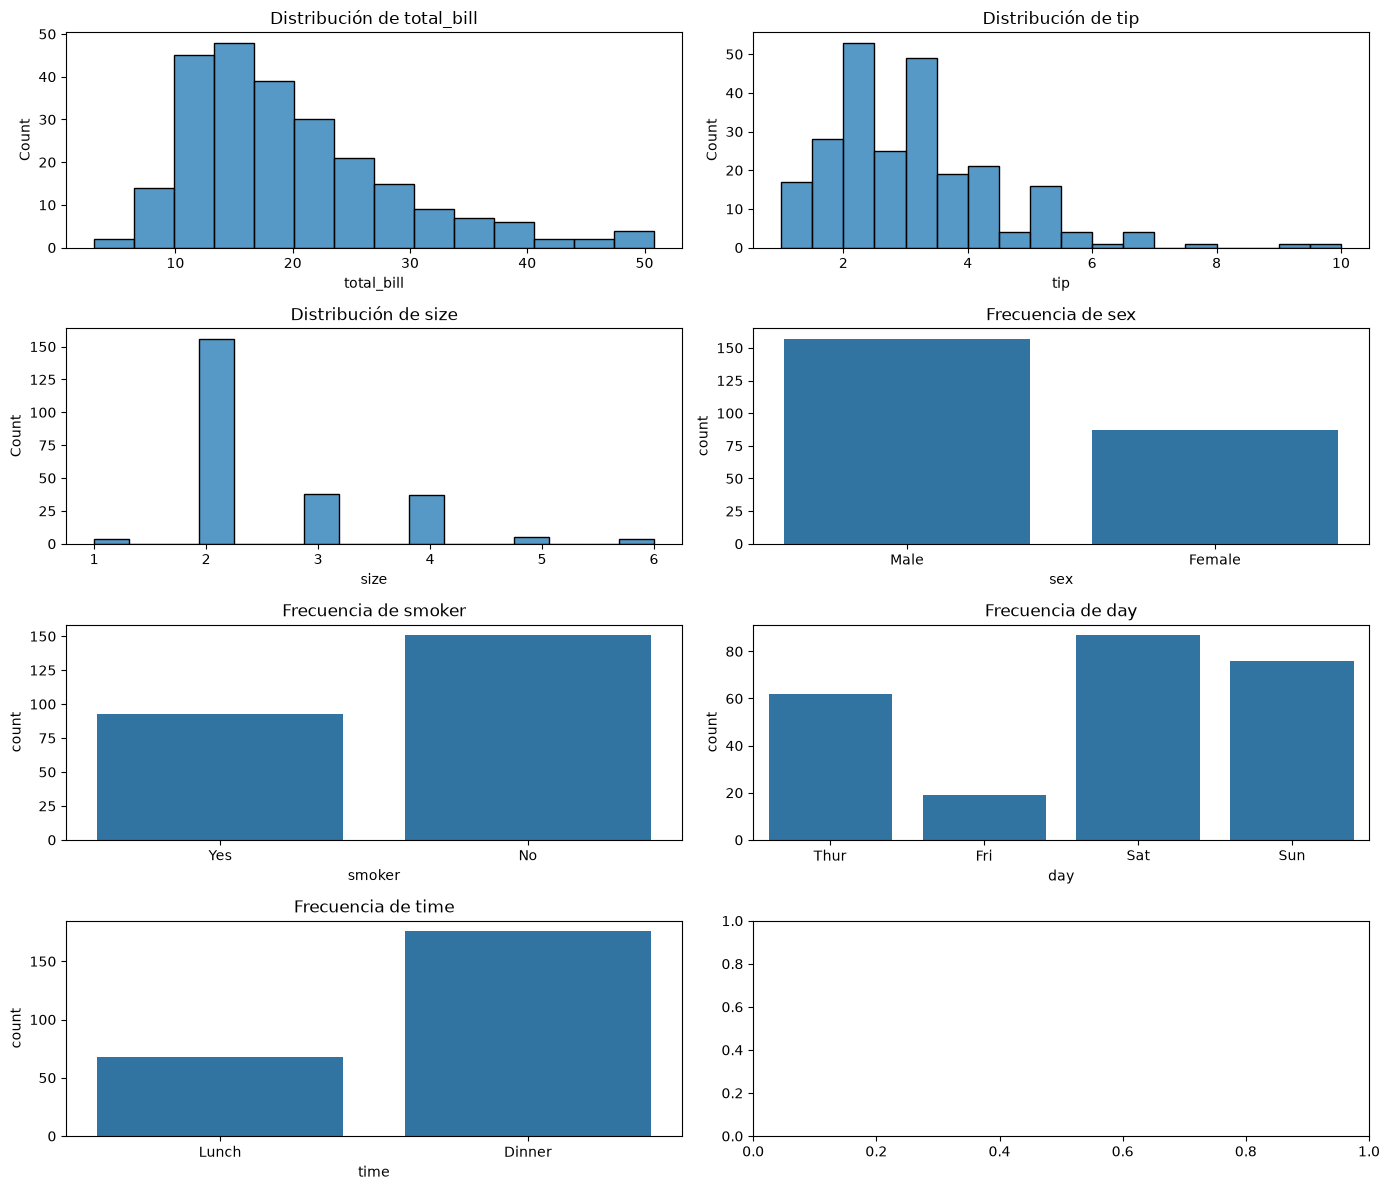

In [3]:
fig, axes = plt.subplots(4, 2, figsize=(14, 12))
axes = axes.flatten()

num_cols = ["total_bill", "tip", "size"]
cat_cols = ["sex", "smoker", "day", "time"]

for i, col in enumerate(num_cols):
    sns.histplot(data=df_tips, x=col, ax=axes[i])
    axes[i].set_title(f"Distribución de {col}")

for i, col in enumerate(cat_cols, start=len(num_cols)):
    sns.countplot(data=df_tips, x=col, ax=axes[i])
    axes[i].set_title(f"Frecuencia de {col}")

plt.tight_layout()
plt.show()

In [4]:
# Veamos que atributos están más corelacionados

matriz_correlacion = df_tips.corr(numeric_only=True)
print(matriz_correlacion["tip"].sort_values(ascending=False))

matriz_correlacion.style.background_gradient()

tip           1.000000
total_bill    0.675734
size          0.489299
Name: tip, dtype: float64


,total_bill,tip,size
total_bill,1.000000,0.675734,0.598315
tip,0.675734,1.000000,0.489299
size,0.598315,0.489299,1.000000


<Axes: xlabel='total_bill', ylabel='tip'>

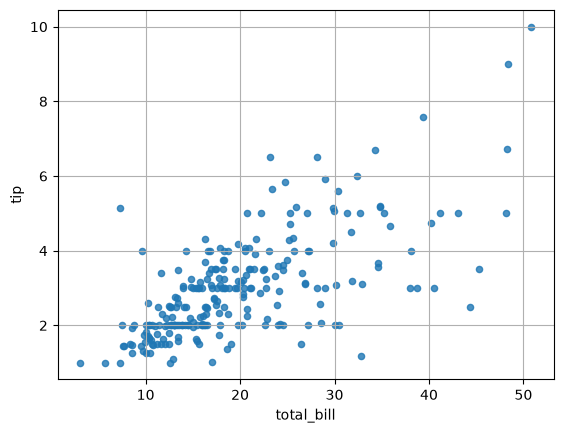

In [5]:
# Creo que es mas útil el porcentaje de propina respecto a la cuenta total que el monto total de propina para observar las correlaciones con las columnas categóricas

df_tips.plot(kind="scatter", x="total_bill", y="tip", grid=True, alpha=0.8)

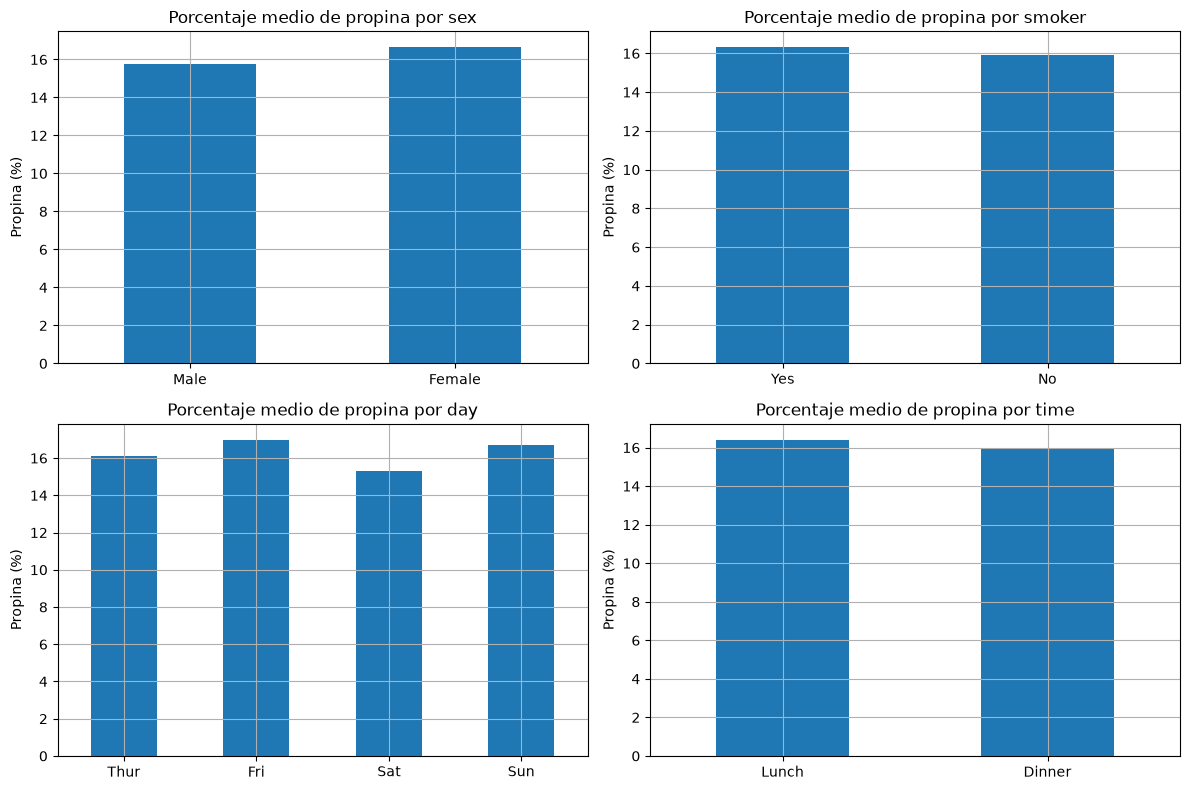

In [6]:
# Ahora queremos ver la relacion entre el porcentaje de propina que dejan los clientes respecto a las variables categoricas, para poder ver su correlacion

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

df_tips["tip_pct"] = df_tips["tip"] / df_tips["total_bill"] * 100

for ax, columna in zip(axes.flat, cat_cols):
    df_tips.groupby(columna)["tip_pct"].mean().plot(
        kind="bar",
        ax=ax,
        title=f"Porcentaje medio de propina por {columna}",
        grid=True
    )
    ax.set_ylabel("Propina (%)")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

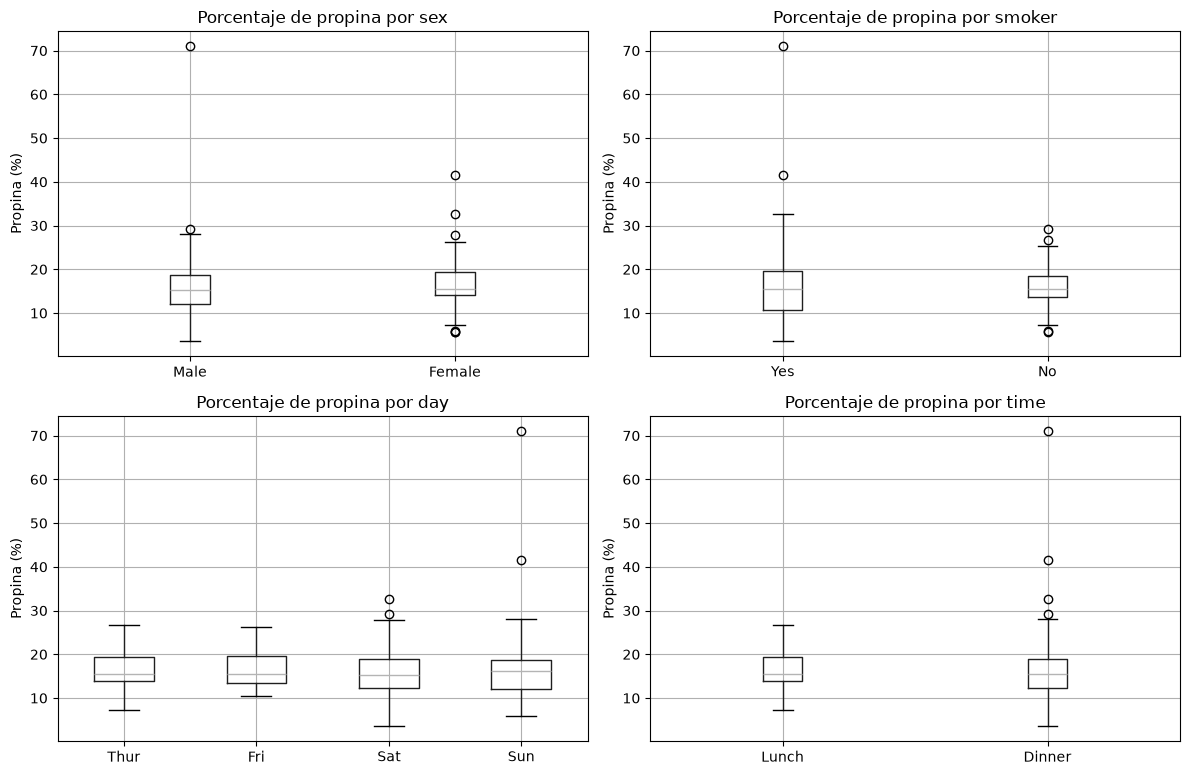

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, columna in zip(axes.flat, cat_cols):
    df_tips.boxplot(
        column="tip_pct",
        by=columna,
        ax=ax,
        grid=True
    )

    ax.set_title(f"Porcentaje de propina por {columna}")
    ax.set_xlabel("")
    ax.set_ylabel("Propina (%)")

plt.suptitle("")
plt.tight_layout()
plt.show()

In [8]:
# Eliminamos tip_pct, como es una columna calculada a partir de tip, no nos vale para tratar de predecir tip, viciaría el modelo

df_tips.drop(columns=["tip_pct"], inplace=True)

### DIVIDIR LOS DATOS

In [9]:
# Quiero mantener la misma proporcion de datos respecto a total_bill, pero la funcion train_test_split necesita que la columna de estratificacion sea categorica, por lo que vamos a crear una columna temporal total_bill_cat

df_tips["total_bill_cat"] = pd.cut(
    df_tips["total_bill"],
    bins=[0, 10, 20, 30, np.inf],
    labels=[1, 2, 3, 4]
)

df_tips["total_bill_cat"].value_counts().sort_index()
df_tips["total_bill_cat"].value_counts(normalize=True).sort_index()

original_train_set, test_set = train_test_split(df_tips, train_size=0.8, stratify=df_tips["total_bill_cat"], random_state=42)
train_set = original_train_set.copy()
train_set: pd.DataFrame

display(train_set["total_bill_cat"].value_counts(normalize=True).sort_index())
display(test_set["total_bill_cat"].value_counts(normalize=True).sort_index())


total_bill_cat
1    0.071795
2    0.533333
3    0.266667
4    0.128205
Name: proportion, dtype: float64

total_bill_cat
1    0.061224
2    0.530612
3    0.265306
4    0.142857
Name: proportion, dtype: float64

### PREPARAR LOS DATOS

In [10]:
# Como en la fase de exploracion hemos visto que no hay valores nulos, realmente no necesitamos tratarlos, pero igualmente lo dejaremos preparado por si en una nueva muestra de datos nos entrase algun nulo, poder utilizar el modelo tal cual

total_bill_pipeline = make_pipeline(
    SimpleImputer(strategy="mean"),
    StandardScaler(),
)

size_pipeline = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    StandardScaler(),
)

categoric_pipeline = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(handle_unknown="ignore", sparse_output=False),
)

preprocessing = ColumnTransformer([
    ("total_bill", total_bill_pipeline, ["total_bill"]),
    ("size", size_pipeline, ["size"]),
    ("categories", categoric_pipeline, ["sex", "smoker", "day", "time"]),
])

## ENTRENAMIENTO Y EVALUACIÓN DEL MODELO

No hacer de momento

## OPTIMIZACIÓN DEL MODELO

No hacer de momento

### EVALUACIÓN EN EL CONJUNTO DE PRUEBA

No hacer de momento

## PRESENTACIÓN DE LA SOLUCIÓN

Ahora tienes que crear un archivo .py con todo lo necesario para que ejecute el modelo que acabamos de crear, en concreto el script tiene que ejecutar lo siguiente:
- Pedir un csv para predecir los datos (suponemos que los datos en el csv están bien)
- Cargamos los datos del csv en un dataframe.
- Aplicamos nuestro modelo al dataframe.
- Informamos al usuario de las predicciones.